# Industry Project: Visual Defect Inspection on a Production Line (Production-Style)

> **Who is this notebook for?** Someone who has never trained an image model for a real business problem.
> You do **not** need the math from the other notebooks in this folder. Every step is explained in plain English, and almost every line of code has a comment.
> Everything runs on a normal laptop CPU in a few minutes. The only download is a small pretrained network (MobileNetV3-Small, ~10 MB).

---

### How this notebook is different from `02_image_classification.ipynb`

| `02_image_classification.ipynb` and the theory notes | This notebook |
|---|---|
| Explains CNN architectures, augmentation, transfer learning and Grad-CAM **in general** | Uses them to solve **one concrete factory problem end to end** |
| Clean benchmark data (CIFAR-10, ImageNet) with balanced classes | Camera images with **lighting changes, dust, glare, broken frames** and only **~15% defects** |
| Accuracy / top-k accuracy | **Recall on defects at a chosen threshold**, false-alarm rate, cost in $ |
| Stops after training | Validation of images, baseline, error gallery, explanation, saving, an **inference function**, a **latency check**, tests and a drift check |

---

### The business problem

You work for a company that machines **brushed-metal covers** (for example, the back plate of a laptop or a kitchen appliance). At the end of the line, a camera takes one photo of every part. Today, two human inspectors look at the photos and reject parts with **scratches, spots (pits/stains) or cracks**.

- A **missed defect** (the part ships to a customer) costs about **$150** (return, replacement, angry customer).
- A **false alarm** (a good part is sent to manual re-inspection) costs about **$2** (one minute of an inspector's time).
- The line produces **~5 parts per second at peak**, so the model must answer in well under **200 ms per image** on an ordinary industrial PC (no GPU).

**What success means:** catch **at least 95% of defective parts** (recall ≥ 0.95) while sending as few good parts to re-inspection as possible. Missing a defect is 75× more expensive than a false alarm, so we deliberately accept more false alarms.

> **Real-world reference:** the public benchmark for this kind of problem is **MVTec AD** (5,000+ high-resolution images of 15 industrial object and texture categories with pixel-precise defect masks). Its licence (CC BY-NC-SA 4.0) and size (~5 GB) make it impractical for this notebook, so we **simulate** similar images. The code works the same way on real photos.

---

### The industry workflow we will follow

```
 1. Collect images -> 2. Validate images -> 3. Split -> 4. Augment
                                                           |
 12. Tests & drift <- 11. Latency <- 10. Inference fn <- 9. Save <- 5. Baseline (classic CV)
                                                           |
                       8. Explain (Grad-CAM) <- 7. Threshold & evaluate <- 6. Transfer learning (freeze -> fine-tune)
```

### Table of Contents
1. Setup: imports and one central config
2. Get the data: simulated camera images from the line
3. First look at the data
4. Validate the images (a "data contract" for pictures)
5. Split the data
6. Preprocessing and augmentation
7. Baseline first: a classic computer-vision rule
8. Transfer learning, step 1: frozen backbone
9. Transfer learning, step 2: fine-tune the whole network
10. Choose the decision threshold (recall first)
11. Final, honest evaluation on the test set
12. Error gallery: look at the mistakes
13. Explain the model with Grad-CAM
14. Save the model with its metadata
15. Serve the model: an inference function for one image
16. Latency check
17. Automated tests
18. Monitoring: what happens when the lamp gets darker?
19. Summary, exercises and resources

---
## 1. Setup: imports and one central config

All "magic numbers" (image size, costs, learning rates, the recall target) live in **one config object**. If the factory says "a missed defect now costs $300", you change one line.

We also:
- fix the **random seeds** so every run gives the same result (reproducibility),
- limit PyTorch to a few CPU threads (this notebook runs on a shared CPU; on a dedicated machine you would use all cores),
- use `logging` instead of `print` for status messages, as production code does.

In [1]:
# ---- Standard library ----
import copy                      # to keep a copy of the best model weights during training
import hashlib                   # to detect duplicate images by their content "fingerprint"
import json                      # to save model metadata as readable text
import logging                   # professional alternative to print() for status messages
import tempfile                  # temporary folder for the saved model (we never write into the repo)
import time                      # to measure training time and latency
import warnings                  # to hide noisy library warnings in this tutorial
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party libraries ----
import cv2                       # OpenCV: classic image processing (drawing, filtering)
import matplotlib.pyplot as plt  # plotting
import numpy as np               # fast numerical arrays (an image is just a NumPy array)
import pandas as pd              # tables
import torch                     # deep learning framework
import torchvision               # pretrained vision models + image transforms
from torch import nn
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from torchvision.transforms import v2 as T          # the modern torchvision transforms API
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("defect_inspection")


@dataclass(frozen=True)              # frozen=True: the config cannot be changed by accident later
class Config:
    seed: int = 42                   # same seed => same images, same split, same model
    image_size: int = 128            # camera crops are 128 x 128 pixels (RGB)
    n_images: int = 1600             # images collected from the line for this project
    defect_rate: float = 0.15        # ~15% of parts are defective in this (enriched) sample
    val_size: float = 0.20           # 20% for validation (model selection + threshold)
    test_size: float = 0.20          # 20% locked away for the final exam
    batch_size: int = 32
    head_epochs: int = 30            # step 1: train only the new head (fast, on cached features)
    finetune_epochs: int = 5         # step 2: fine-tune the upper part of the network (slower)
    frozen_blocks: int = 4           # the first 4 backbone blocks (generic edges/colours) stay frozen
    lr_head: float = 2e-3            # learning rate for the classification head
    lr_backbone: float = 1e-3        # smaller learning rate for the pretrained layers
    target_recall: float = 0.95      # business requirement: catch >= 95% of defects
    cost_missed_defect: float = 150.0   # $ per defective part that reaches a customer
    cost_false_alarm: float = 2.0       # $ per good part sent to manual re-inspection
    latency_budget_ms: float = 200.0    # 5 parts per second => at most 200 ms per image
    num_threads: int = 2             # CPU threads for PyTorch (shared machine)


CFG = Config()
torch.manual_seed(CFG.seed)
np.random.seed(CFG.seed)
torch.set_num_threads(CFG.num_threads)
log.info("torch %s | torchvision %s | OpenCV %s", torch.__version__, torchvision.__version__, cv2.__version__)
print(CFG)

2026-10-21 17:49:16,187 | INFO | torch 2.12.1+cpu | torchvision 0.27.1+cpu | OpenCV 5.0.0


Config(seed=42, image_size=128, n_images=1600, defect_rate=0.15, val_size=0.2, test_size=0.2, batch_size=32, head_epochs=30, finetune_epochs=5, frozen_blocks=4, lr_head=0.002, lr_backbone=0.001, target_recall=0.95, cost_missed_defect=150.0, cost_false_alarm=2.0, latency_budget_ms=200.0, num_threads=2)


---
## 2. Get the data: simulated camera images from the line

In a real project the images come from the line camera and are stored with a **production log** (part ID, timestamp, shift, and the inspector's verdict). Loading them would look like:

```python
# Real-life version (not run here):
# log_df = pd.read_sql("SELECT part_id, image_path, inspector_label FROM inspections WHERE day >= '2026-09-01'", engine)
# images = [cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in log_df.image_path]   # OpenCV loads BGR!
```

Here we **generate** images that behave like real ones:
- **Brushed-metal texture** whose direction and position vary a little from part to part.
- **Lighting changes:** brighter/darker exposure, a light gradient and vignetting, a small colour tint.
- **Harmless "nuisances" on good parts:** dust specks, glare from the lamp, faint oil smudges. These look a bit like defects and are the main source of false alarms in real factories.
- **Three defect types** with **random severity** (contrast): thin **scratches**, round **spots**, branching **cracks**. Some are very faint and hard even for a human.
- **Broken data:** a few black frames (camera dropout), over-exposed frames, a wrongly sized crop, and parts photographed twice.

You can skip the generator details; just know that each image comes with its true label, defect type, severity and defect position.

In [2]:
SIZE = CFG.image_size
YY, XX = np.mgrid[0:SIZE, 0:SIZE].astype(np.float32)        # pixel coordinate grids, reused below


def soft_blob(cx, cy, radius):
    """A soft round spot (Gaussian) centred at (cx, cy). Used for dust, glare, smudges and spots."""
    return np.exp(-((XX - cx) ** 2 + (YY - cy) ** 2) / (2 * radius ** 2))


def brushed_metal(rng):
    """Brushed-metal texture: noise smeared in one direction, slightly rotated and shifted per part."""
    big = int(SIZE * 1.5)
    noise = rng.normal(0, 1, (big, big)).astype(np.float32)
    streaks = cv2.GaussianBlur(noise, (0, 0), sigmaX=rng.uniform(8, 16), sigmaY=0.7)   # long thin streaks
    streaks /= streaks.std() + 1e-6
    rotation = cv2.getRotationMatrix2D((big / 2, big / 2), rng.uniform(-12, 12), 1.0)  # part not perfectly aligned
    streaks = cv2.warpAffine(streaks, rotation, (big, big), borderMode=cv2.BORDER_REFLECT)
    offset = (big - SIZE) // 2 + rng.integers(-8, 9)                                     # position jitter
    return streaks[offset:offset + SIZE, offset:offset + SIZE]


def lighting_pattern(rng):
    """Uneven illumination: a linear gradient plus a vignette (darker away from the light centre)."""
    angle = rng.uniform(0, 2 * np.pi)
    gradient = (np.cos(angle) * (XX / SIZE - .5) + np.sin(angle) * (YY / SIZE - .5)) * rng.uniform(0.1, 0.35)
    cx, cy = rng.uniform(0.2, 0.8, 2) * SIZE
    vignette = -rng.uniform(0.0, 0.25) * (((XX - cx) / SIZE) ** 2 + ((YY - cy) / SIZE) ** 2)
    return gradient + vignette


def draw_defect(rng, kind):
    """Return (mask, sign, centre_x, centre_y, extent): where the defect is and whether it is darker (-1) or brighter (+1)."""
    mask = np.zeros((SIZE, SIZE), np.float32)
    cx, cy = rng.integers(20, SIZE - 20, 2)                  # keep defects away from the border
    sign = -1
    if kind == "scratch":                                    # thin straight line, dark or shiny
        length, angle = rng.uniform(15, 50), rng.uniform(0, np.pi)
        dx, dy = length / 2 * np.cos(angle), length / 2 * np.sin(angle)
        cv2.line(mask, (int(cx - dx), int(cy - dy)), (int(cx + dx), int(cy + dy)), 1.0, 1, cv2.LINE_AA)
        sign = rng.choice([-1, 1])
    elif kind == "spot":                                     # small round pit or stain
        cv2.circle(mask, (int(cx), int(cy)), int(rng.integers(2, 6)), 1.0, -1, cv2.LINE_AA)
        mask = cv2.GaussianBlur(mask, (0, 0), 0.8)
    else:                                                    # crack: a thin random zig-zag path
        points, angle = [(cx, cy)], rng.uniform(0, 2 * np.pi)
        for _ in range(rng.integers(5, 10)):
            angle += rng.normal(0, 0.6)
            step = rng.uniform(3, 7)
            points.append((points[-1][0] + step * np.cos(angle), points[-1][1] + step * np.sin(angle)))
        cv2.polylines(mask, [np.array(points, np.int32)], False, 1.0, 1, cv2.LINE_AA)
    ys, xs = np.nonzero(mask > 0.3)                          # pixels that belong to the defect
    centre_x, centre_y = xs.mean(), ys.mean()                # centre of the defect (a crack wanders away from its start)
    extent = float(np.max(np.hypot(xs - centre_x, ys - centre_y)))   # how far it reaches from its centre
    return mask, sign, int(centre_x), int(centre_y), round(extent, 1)


def capture_part(rng, defect_type=None, severity=0.0):
    """Simulate one camera image (uint8 RGB, SIZE x SIZE) and return it with the defect position and size."""
    img = np.full((SIZE, SIZE), rng.uniform(0.45, 0.62), np.float32)          # base grey level of the metal
    img += brushed_metal(rng) * rng.uniform(0.02, 0.05)                       # texture
    img += rng.normal(0, rng.uniform(0.01, 0.03), (SIZE, SIZE)).astype(np.float32)   # sensor noise
    for _ in range(rng.poisson(2.0)):                                         # dust specks (harmless)
        x, y = rng.integers(2, SIZE - 2, 2)
        img += soft_blob(x, y, rng.uniform(0.5, 1.2)) * rng.choice([-1, 1]) * rng.uniform(0.04, 0.15)
    if rng.random() < 0.3:                                                    # lamp glare (harmless)
        img += soft_blob(*rng.uniform(10, SIZE - 10, 2), rng.uniform(6, 16)) * rng.uniform(0.1, 0.3)
    if rng.random() < 0.25:                                                   # oil smudge (harmless)
        img -= soft_blob(*rng.uniform(10, SIZE - 10, 2), rng.uniform(5, 12)) * rng.uniform(0.04, 0.1)
    cx = cy = -1; extent = 0.0
    if defect_type is not None:
        mask, sign, cx, cy, extent = draw_defect(rng, defect_type)
        img += sign * severity * mask
    img = img * rng.uniform(0.8, 1.2) + lighting_pattern(rng)                 # exposure + uneven light
    rgb = img[..., None] * (1 + rng.normal(0, 0.03, 3))[None, None, :]        # slight colour tint
    return (np.clip(rgb, 0, 1) * 255).astype(np.uint8), cx, cy, extent


def collect_line_images(n_images, seed):
    """Return (list of images, metadata DataFrame), including some broken frames like a real camera."""
    rng = np.random.default_rng(seed)
    images, rows = [], []
    for i in range(n_images):
        is_defect = rng.random() < CFG.defect_rate
        defect_type = str(rng.choice(["scratch", "spot", "crack"])) if is_defect else None
        severity = float(rng.uniform(0.10, 0.35)) if is_defect else 0.0       # contrast of the defect
        img, cx, cy, extent = capture_part(rng, defect_type, severity)
        images.append(img)
        rows.append({"part_id": f"P{100000 + i}", "shift": rng.choice(["early", "late", "night"]),
                     "label": int(is_defect), "defect_type": defect_type or "none",
                     "severity": round(severity, 3), "defect_x": cx, "defect_y": cy, "defect_extent": extent})
    meta = pd.DataFrame(rows)

    # ---- Real cameras produce broken data. Add some on purpose. ----
    for i in rng.choice(n_images, 6, replace=False):
        images[i] = np.zeros_like(images[i])                                  # camera dropout: black frame
    for i in rng.choice(n_images, 4, replace=False):
        images[i] = np.full_like(images[i], 254)                              # over-exposed: flash fired twice
    for i in rng.choice(n_images, 2, replace=False):
        images[i] = images[i][:, :96]                                         # wrong crop size from a config bug
    dup_src = rng.choice(n_images, 8, replace=False)                          # PLC triggered the camera twice
    images += [images[i].copy() for i in dup_src]
    meta = pd.concat([meta, meta.iloc[dup_src].assign(part_id=lambda d: d.part_id + "-retake")],
                     ignore_index=True)
    return images, meta


t0 = time.time()
raw_images, raw_meta = collect_line_images(CFG.n_images, CFG.seed)
log.info("Collected %d images in %.1fs", len(raw_images), time.time() - t0)
raw_meta.head()

2026-10-21 17:49:25,657 | INFO | Collected 1608 images in 9.4s


,part_id,shift,label,defect_type,severity,defect_x,defect_y,defect_extent
0,P100000,night,0,none,0.000,-1,-1,0.0
1,P100001,night,0,none,0.000,-1,-1,0.0
2,P100002,night,0,none,0.000,-1,-1,0.0
3,P100003,early,1,spot,0.137,28,34,5.7
4,P100004,early,1,crack,0.198,57,101,17.7


---
## 3. First look at the data

Before any modelling, a professional **looks at the pictures** and answers three questions:
1. **How balanced are the classes?** With 15% defects, a model that always says "good" is 85% accurate and completely useless.
2. **What do the classes look like?** Are defects visible to a human? Are there look-alikes (dust, glare)?
3. **How hard are the defects?** Faint defects are where models (and humans) fail.

Images collected: 1608
Defect rate     : 13.7%

Defect types:
defect_type
none       1387
crack        84
spot         71
scratch      66


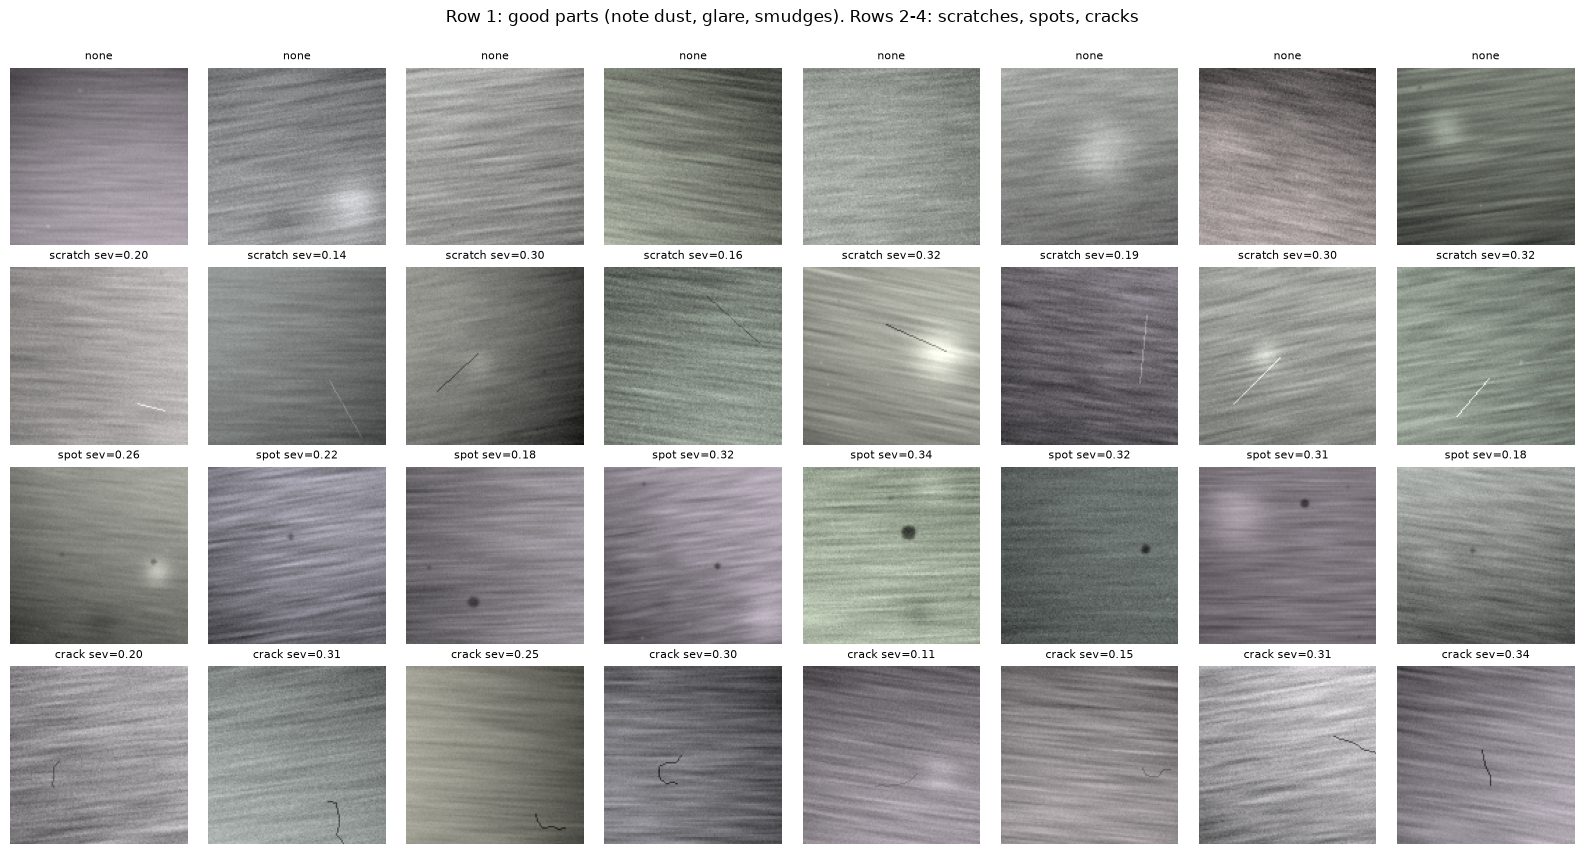

In [3]:
print("Images collected:", len(raw_images))
print("Defect rate     :", f"{raw_meta['label'].mean():.1%}")
print("\nDefect types:")
print(raw_meta["defect_type"].value_counts().to_string())

# A gallery: one row of good parts, then one row per defect type
fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
rng_view = np.random.default_rng(0)
for row, kind in enumerate(["none", "scratch", "spot", "crack"]):
    looks_ok = [i for i in raw_meta.index[raw_meta.defect_type == kind] if raw_images[i].shape == (SIZE, SIZE, 3)
                and 15 < raw_images[i].mean() < 240]                           # skip broken frames for this preview
    ids = rng_view.choice(looks_ok, 8, replace=False)
    for ax, i in zip(axes[row], ids):
        ax.imshow(raw_images[i])
        ax.set_title(f"{kind}" + (f" sev={raw_meta.severity[i]:.2f}" if kind != "none" else ""), fontsize=8)
        ax.axis("off")
plt.suptitle("Row 1: good parts (note dust, glare, smudges). Rows 2-4: scratches, spots, cracks", y=1.0)
plt.tight_layout(); plt.show()

**What we see:** good parts are *not* perfectly clean (dust specks, glare, smudges), and low-severity defects are hard to see even for us. That is exactly what makes visual inspection difficult in practice, and why simple rules ("any dark pixel = defect") produce many false alarms.

---
## 4. Validate the images (a "data contract" for pictures)

Images break in different ways than tables. Typical checks before training (and before every prediction in production):

| Check | Catches |
|---|---|
| shape = (128, 128, 3), dtype = uint8 | wrong crop, grayscale camera, float images |
| mean brightness between 15 and 240 | black frames (camera dropout), over-exposed frames |
| standard deviation > 2 | flat / frozen frames |
| content hash is unique | the same part photographed twice (would leak between train and test!) |

We write the check as a **function** that returns a list of problems, so we can reuse it in the inference service later.

In [4]:
EXPECTED_SHAPE = (CFG.image_size, CFG.image_size, 3)


def validate_image(img) -> list:
    """Return a list of problems with this image (an empty list means the image is OK)."""
    if not isinstance(img, np.ndarray):
        return ["not a numpy array"]
    problems = []
    if img.shape != EXPECTED_SHAPE:
        problems.append(f"shape {img.shape} != {EXPECTED_SHAPE}")
    if img.dtype != np.uint8:
        problems.append(f"dtype {img.dtype} != uint8")
    if img.size and not problems:                       # only check pixels if the format is right
        mean, std = float(img.mean()), float(img.std())
        if mean < 15:
            problems.append(f"too dark (mean={mean:.0f}) - camera dropout?")
        if mean > 240:
            problems.append(f"over-exposed (mean={mean:.0f})")
        if std < 2:
            problems.append(f"almost no texture (std={std:.1f}) - frozen frame?")
    return problems


def image_fingerprint(img) -> str:
    """MD5 hash of the pixel bytes: identical images get identical fingerprints."""
    return hashlib.md5(np.ascontiguousarray(img).tobytes()).hexdigest()


report = raw_meta[["part_id"]].copy()
report["problems"] = ["; ".join(validate_image(im)) for im in raw_images]
report["fingerprint"] = [image_fingerprint(im) for im in raw_images]
report["is_duplicate"] = report["fingerprint"].duplicated(keep="first")

bad = report["problems"] != ""
print(f"Invalid images  : {bad.sum()}")
print(f"Duplicate images: {report['is_duplicate'].sum()}")
print(report.loc[bad, "problems"].str.split(" \\(").str[0].value_counts().to_string())

keep = ~bad & ~report["is_duplicate"]
images = np.stack([raw_images[i] for i in np.flatnonzero(keep)])      # one (N, 128, 128, 3) uint8 array
meta = raw_meta[keep].reset_index(drop=True)
log.info("Clean dataset: %d images, %.1f%% defects", len(images), 100 * meta.label.mean())

2026-10-21 17:49:32,070 | INFO | Clean dataset: 1588 images, 13.9% defects


Invalid images  : 12
Duplicate images: 16
problems
too dark        6
over-exposed    4
shape           2


In production, invalid images are **not** silently dropped: they trigger an alert ("camera 3 is sending black frames") and the part goes to manual inspection. Silently feeding a black frame to the model would produce a confident but meaningless answer.

---
## 5. Split the data

Three sets, created **before** any training:

| Set | Size | Used for |
|---|---|---|
| Train | 60% | learning the weights |
| Validation | 20% | choosing the number of epochs and the **decision threshold** |
| Test | 20% | the final exam, used **once** |

`stratify` keeps the same defect rate *and* the same mix of defect types in each set.

> **Industry note:** in a real factory, photos of the same part or the same production batch are very similar. Split by **batch or by day** (e.g. `GroupShuffleSplit` on `batch_id`), otherwise near-identical images end up in train and test and the score looks better than reality. Here we already removed exact duplicates in Section 4.

In [5]:
idx_all = np.arange(len(meta))
strata = meta["defect_type"]                                   # stratify by type (includes "none")
idx_trainval, idx_test = train_test_split(idx_all, test_size=CFG.test_size, stratify=strata,
                                          random_state=CFG.seed)
idx_train, idx_val = train_test_split(idx_trainval, test_size=CFG.val_size / (1 - CFG.test_size),
                                      stratify=strata[idx_trainval], random_state=CFG.seed)

y_all = meta["label"].to_numpy()
for name, idx in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    print(f"{name:5s}: {len(idx):4d} images | {y_all[idx].sum():3d} defects ({y_all[idx].mean():.1%})")

train:  952 images | 133 defects (14.0%)
val  :  318 images |  44 defects (13.8%)
test :  318 images |  44 defects (13.8%)


Notice how **small** the number of defects is: only 44 in validation and in test. That means every single missed defect moves recall by more than 2 percentage points. Keep this in mind when reading the results (we will add an uncertainty interval).

---
## 6. Preprocessing and augmentation

### Preprocessing must be identical in training and production
A pretrained network expects images prepared **exactly** as during its own training: pixel values scaled to 0-1 and then normalised with the ImageNet mean and standard deviation. We define this **once** (`EVAL_TRANSFORM`) and reuse the same object in validation, testing *and* the inference service. A different resize or normalisation in production is one of the most common causes of "the model worked in the notebook but not in the factory".

### Augmentation: only variations that really happen
Augmentation creates slightly changed copies of training images so the model learns to ignore irrelevant changes. The rule: **only simulate variations you will see on the line.**
- Flips: a scratch is a scratch whether it points left or right. ✔
- Small shifts / rotations: parts are never placed perfectly. ✔
- Brightness / contrast changes: the lamp ages, the shift changes. ✔
- Large rotations of 90°: would turn horizontal brushing vertical, which never happens on this camera. ✘
- Colour (hue) changes: the metal is always grey. ✘
- Heavy blur: would erase the faint defects we are trying to find. ✘

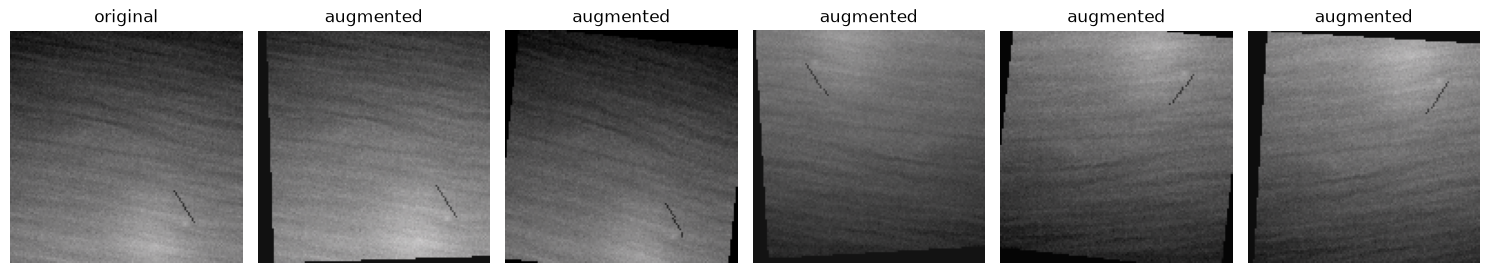

In [6]:
weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1        # pretrained weights (tells us mean/std too)
IMAGENET_MEAN = weights.transforms().mean                 # [0.485, 0.456, 0.406]
IMAGENET_STD = weights.transforms().std                   # [0.229, 0.224, 0.225]

# Used for validation, test AND production: deterministic, no randomness
EVAL_TRANSFORM = T.Compose([
    T.ToImage(),                                          # numpy HxWxC uint8 -> torch CxHxW uint8
    T.ToDtype(torch.float32, scale=True),                 # 0..255 -> 0.0..1.0
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),             # same statistics the backbone was trained with
])

# Used ONLY for training: random, realistic changes + the same preprocessing at the end
TRAIN_TRANSFORM = T.Compose([
    T.ToImage(),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomAffine(degrees=8, translate=(0.06, 0.06)),    # small rotation + shift (placement jitter)
    T.ColorJitter(brightness=0.25, contrast=0.25),        # lighting changes
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class SurfaceDataset(torch.utils.data.Dataset):
    """Wraps the image array + labels so PyTorch can load them in batches."""

    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        x = self.transform(self.images[i])                          # preprocess (+ augment if training)
        y = torch.tensor(self.labels[i], dtype=torch.float32)
        return x, y


def make_loader(idx, train: bool):
    ds = SurfaceDataset(images[idx], y_all[idx], TRAIN_TRANSFORM if train else EVAL_TRANSFORM)
    return torch.utils.data.DataLoader(ds, batch_size=CFG.batch_size, shuffle=train, num_workers=0)


train_loader, val_loader, test_loader = make_loader(idx_train, True), make_loader(idx_val, False), make_loader(idx_test, False)

# Show what augmentation does to ONE defective training image
example = images[idx_train[np.flatnonzero(y_all[idx_train])[0]]]
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
axes[0].imshow(example); axes[0].set_title("original")
for ax in axes[1:]:
    aug = TRAIN_TRANSFORM(example)                                           # normalised tensor
    shown = (aug * torch.tensor(IMAGENET_STD)[:, None, None] + torch.tensor(IMAGENET_MEAN)[:, None, None])
    ax.imshow(shown.permute(1, 2, 0).clamp(0, 1).numpy()); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

---
## 7. Baseline first: a classic computer-vision rule

Before deep learning, factories used (and many still use) **hand-written rules**: remove the smooth background, then flag the part if any pixel deviates too much. This is fast, needs no training data, and is easy to explain. Any neural network **must beat it**, otherwise it is not worth the extra complexity.

Our rule:
1. Convert to grayscale and lightly blur (reduces sensor noise).
2. Subtract a **median-filtered** version (median filtering removes thin lines and small spots, so the difference *keeps* them).
3. The "defect score" is the 99.9th percentile of the absolute difference (robust "maximum").

We pick the rule's threshold on train + validation images so that it reaches the same **95% recall** target, then check it on the test set.

Classic rule threshold: 17.4 grey levels
Classic rule on TEST : {'recall_defects': 0.977, 'false_alarm_rate': 0.704, 'precision': 0.182, 'missed_defects': 1, 'false_alarms': 193, 'cost_usd': 536.0, 'roc_auc': 0.791, 'pr_auc': 0.488}


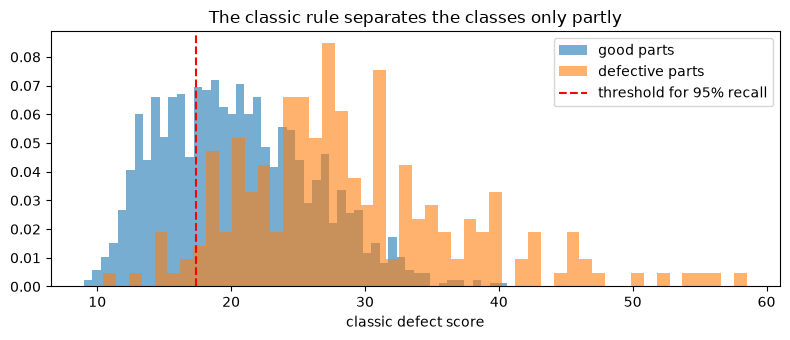

In [7]:
def classic_defect_score(img: np.ndarray) -> float:
    """Background subtraction score: high when there are thin/small structures that differ from the surroundings."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)                      # remove pixel noise
    background = cv2.medianBlur(gray.astype(np.uint8), 11).astype(np.float32)   # smooth surface estimate
    residual = np.abs(gray - background)                           # what does not belong to the surface
    return float(np.percentile(residual, 99.9))


def threshold_for_recall(y_true, scores, target_recall):
    """Highest threshold that still flags at least `target_recall` of the defects."""
    defect_scores = np.sort(scores[y_true == 1])
    k = int(np.floor((1 - target_recall) * len(defect_scores)))      # how many defects we may miss
    return float(defect_scores[k])


def inspection_metrics(y_true, scores, threshold) -> dict:
    """Business-oriented metrics for a given threshold."""
    flagged = scores >= threshold
    tp, fn = int(np.sum(flagged & (y_true == 1))), int(np.sum(~flagged & (y_true == 1)))
    fp, tn = int(np.sum(flagged & (y_true == 0))), int(np.sum(~flagged & (y_true == 0)))
    return {"recall_defects": round(tp / max(tp + fn, 1), 3),
            "false_alarm_rate": round(fp / max(fp + tn, 1), 3),     # share of GOOD parts sent to re-inspection
            "precision": round(tp / max(tp + fp, 1), 3),
            "missed_defects": fn, "false_alarms": fp,
            "cost_usd": fn * CFG.cost_missed_defect + fp * CFG.cost_false_alarm,
            "roc_auc": round(roc_auc_score(y_true, scores), 3),
            "pr_auc": round(average_precision_score(y_true, scores), 3)}


classic_scores = np.array([classic_defect_score(im) for im in images])
classic_thr = threshold_for_recall(y_all[idx_trainval], classic_scores[idx_trainval], CFG.target_recall)
baseline_test = inspection_metrics(y_all[idx_test], classic_scores[idx_test], classic_thr)
print(f"Classic rule threshold: {classic_thr:.1f} grey levels")
print("Classic rule on TEST :", baseline_test)

plt.figure(figsize=(8, 3.5))
plt.hist(classic_scores[y_all == 0], bins=50, alpha=.6, label="good parts", density=True)
plt.hist(classic_scores[y_all == 1], bins=50, alpha=.6, label="defective parts", density=True)
plt.axvline(classic_thr, color="red", ls="--", label="threshold for 95% recall")
plt.xlabel("classic defect score"); plt.legend(); plt.title("The classic rule separates the classes only partly")
plt.tight_layout(); plt.show()

The rule has some signal, but to catch 95% of defects it must also flag a large share of good parts, because dust specks and glare edges look like "small structures that differ from the surroundings". This is the typical weakness of hand-written rules and the reason factories move to learned models.

---
## 8. Transfer learning, step 1: frozen backbone

We have only ~950 training images. Training a CNN **from scratch** on so little data works badly. Instead we use **transfer learning**: start from a network pretrained on ImageNet (1.2 million photos), which already knows edges, lines, blobs and textures, and teach it only our specific question.

**Why MobileNetV3-Small?** It is tiny (~1.5 M parameters once the 1000-class ImageNet layer is replaced, ~6 MB) and fast on a CPU, which suits an industrial PC next to the line. ResNet-18 or EfficientNet-B0 are common, slightly more accurate but slower alternatives. (Hundreds more are available in `timm`.)

The standard two-step recipe (as in the official PyTorch transfer-learning tutorial):
1. **Freeze** the pretrained backbone and train only a new **head** (the last layer). Fast and safe: the pretrained features cannot be damaged.
2. **Unfreeze** the upper part of the backbone and **fine-tune** it with a small learning rate (Section 9).

Because the frozen backbone never changes in step 1, we compute its features **once** and train the head on those cached features: seconds instead of minutes.

### Handling class imbalance
With 15% defects, the loss is dominated by good parts. We use `BCEWithLogitsLoss(pos_weight=n_good / n_defect)`: a mistake on a defective part counts about 6× more (the exact value is printed below). (Alternatives: oversampling with `WeightedRandomSampler`, or focal loss.)

> ⚠️ Class weighting makes the predicted "probabilities" too high (not calibrated). That is fine here because we choose the threshold on validation data by **recall**, not by trusting the probability values. If you need honest probabilities, calibrate them (see `03_Machine_Learning/01_supervised/13_model_calibration.ipynb`).

In [8]:
def build_model(pretrained: bool = True) -> nn.Module:
    """MobileNetV3-Small with a new 1-output head (logit of 'defective')."""
    model = mobilenet_v3_small(weights=weights if pretrained else None)
    in_features = model.classifier[3].in_features                   # 1024
    model.classifier[3] = nn.Linear(in_features, 1)                 # replace the 1000-class ImageNet layer
    return model


model = build_model()
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params / 1e6:.2f} M")
print("Head:", model.classifier)


@torch.inference_mode()
def backbone_features(model, loader):
    """Pooled backbone output (576 numbers per image) for every image in the loader."""
    model.eval()
    feats, labels = [], []
    for x, y in loader:
        feats.append(model.avgpool(model.features(x)).flatten(1))
        labels.append(y)
    return torch.cat(feats), torch.cat(labels)


t0 = time.time()
train_eval_loader = make_loader(idx_train, train=False)              # no augmentation for cached features
f_train, yf_train = backbone_features(model, train_eval_loader)
f_val, yf_val = backbone_features(model, val_loader)
log.info("Cached backbone features in %.1fs: %s", time.time() - t0, tuple(f_train.shape))

pos_weight = torch.tensor((y_all[idx_train] == 0).sum() / (y_all[idx_train] == 1).sum(), dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(f"pos_weight = {pos_weight.item():.2f}")

# Train ONLY the head (model.classifier) on the cached features
head_opt = torch.optim.AdamW(model.classifier.parameters(), lr=CFG.lr_head, weight_decay=1e-4)
gen = torch.Generator().manual_seed(CFG.seed)
for epoch in range(CFG.head_epochs):
    model.classifier.train()
    for batch in torch.randperm(len(f_train), generator=gen).split(CFG.batch_size):
        head_opt.zero_grad()
        loss = loss_fn(model.classifier(f_train[batch]).squeeze(1), yf_train[batch])
        loss.backward()
        head_opt.step()

model.classifier.eval()
with torch.inference_mode():
    val_scores_frozen = torch.sigmoid(model.classifier(f_val).squeeze(1)).numpy()
frozen_val_ap = average_precision_score(y_all[idx_val], val_scores_frozen)
print(f"Frozen backbone -> validation PR-AUC {frozen_val_ap:.3f} | ROC-AUC {roc_auc_score(y_all[idx_val], val_scores_frozen):.3f}")

Parameters: 1.52 M
Head: Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1, bias=True)
)


2026-10-21 17:49:43,654 | INFO | Cached backbone features in 5.7s: (952, 576)


pos_weight = 6.16


Frozen backbone -> validation PR-AUC 0.876 | ROC-AUC 0.939


**PR-AUC** (average precision) summarises how well defects are ranked above good parts; 1.0 is perfect and the defect rate (~0.15) is what random guessing gets. It is the right summary metric when the interesting class is rare.

ImageNet features are tuned for objects like dogs and cars, not for a 1-pixel-wide scratch on metal, so the frozen model is only a first step.

---
## 9. Transfer learning, step 2: fine-tune the upper part of the network

Now we **unfreeze** most of the backbone and continue training with augmentation. Industry practices used here:
- **Partial unfreezing:** the first 4 blocks (which detect generic edges and colour blobs, useful for any image) stay frozen; the later blocks, which combine them into "objects", adapt to scratches and metal texture. This trains faster and overfits less on small datasets. Frozen blocks are also kept in `eval()` mode so their BatchNorm statistics do not drift (a classic fine-tuning bug).
- **Differential learning rates:** the pretrained backbone gets a smaller learning rate than the head, so we adapt it gently instead of destroying what it learned.
- **Cosine learning-rate schedule:** start higher, slowly decrease to almost zero.
- **Checkpoint the best epoch** on validation PR-AUC (a simple form of early stopping) and restore it at the end.

This is the slow part of the notebook (a few minutes on a CPU; seconds on a GPU).

In [9]:
@torch.inference_mode()
def predict_scores(model, loader) -> np.ndarray:
    """Defect probability (sigmoid of the logit) for every image in the loader."""
    model.eval()
    return torch.cat([torch.sigmoid(model(x).squeeze(1)) for x, _ in loader]).numpy()


for i, block in enumerate(model.features):
    for p in block.parameters():
        p.requires_grad = i >= CFG.frozen_blocks             # unfreeze blocks 4..12, keep 0..3 frozen
trainable_backbone = [p for p in model.features.parameters() if p.requires_grad]
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f} M")
optimizer = torch.optim.AdamW([
    {"params": trainable_backbone, "lr": CFG.lr_backbone},          # gentle on pretrained layers
    {"params": model.classifier.parameters(), "lr": CFG.lr_head},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.finetune_epochs)

history = [{"epoch": 0, "train_loss": None, "val_pr_auc": round(frozen_val_ap, 3), "seconds": None}]
best_ap, best_state = frozen_val_ap, copy.deepcopy(model.state_dict())
for epoch in range(1, CFG.finetune_epochs + 1):
    t0, losses = time.time(), []
    model.train()                                             # training mode: dropout on, BatchNorm updates
    model.features[:CFG.frozen_blocks].eval()                 # ...except in the frozen blocks
    for x, y in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(x).squeeze(1), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    scheduler.step()
    val_ap = average_precision_score(y_all[idx_val], predict_scores(model, val_loader))
    history.append({"epoch": epoch, "train_loss": round(float(np.mean(losses)), 4),
                    "val_pr_auc": round(val_ap, 3), "seconds": round(time.time() - t0, 1)})
    log.info("epoch %d | loss %.4f | val PR-AUC %.3f | %.0fs", epoch, np.mean(losses), val_ap, time.time() - t0)
    if val_ap > best_ap:                                      # keep the best checkpoint
        best_ap, best_state = val_ap, copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
history_df = pd.DataFrame(history)
print(history_df.to_string(index=False))
print(f"\nBest validation PR-AUC: {best_ap:.3f} (epoch 0 = frozen backbone)")

Trainable parameters: 1.51 M


2026-10-21 17:50:07,969 | INFO | epoch 1 | loss 3.2517 | val PR-AUC 0.814 | 16s


2026-10-21 17:50:22,908 | INFO | epoch 2 | loss 0.6655 | val PR-AUC 0.850 | 15s


2026-10-21 17:50:39,434 | INFO | epoch 3 | loss 0.4988 | val PR-AUC 0.884 | 17s


2026-10-21 17:50:57,234 | INFO | epoch 4 | loss 0.4861 | val PR-AUC 0.899 | 18s


2026-10-21 17:51:17,075 | INFO | epoch 5 | loss 0.3415 | val PR-AUC 0.902 | 20s


 epoch  train_loss  val_pr_auc  seconds
     0         NaN       0.876      NaN
     1      3.2517       0.814     15.7
     2      0.6655       0.850     14.9
     3      0.4988       0.884     16.5
     4      0.4861       0.899     17.8
     5      0.3415       0.902     19.8

Best validation PR-AUC: 0.902 (epoch 0 = frozen backbone)


Epoch 0 is the frozen-backbone model from Section 8. Compare it with the fine-tuned epochs: the frozen ImageNet features are already a strong start here, and adapting the upper backbone to metal textures adds a further, moderate improvement in validation PR-AUC. (With real, subtler defects the gain from fine-tuning is often larger; with very little data it can be zero. Always measure it, as here.) The first fine-tuning epoch is not always better than the frozen model (the new, large gradients shake the pretrained weights); the cosine schedule and the best-checkpoint logic protect us from shipping such a model.

---
## 10. Choose the decision threshold (recall first)

The network outputs a score between 0 and 1. We need a **cut-off**: "reject the part if score ≥ *T*". The default 0.5 is arbitrary, and with class weighting it is not even "50% probability".

The business rule is **recall ≥ 95% on defects**. So on the **validation** set we choose the **highest** threshold that still catches 95% of defects (higher threshold = fewer false alarms). We also show the money view: total cost = missed defects × $150 + false alarms × $2.

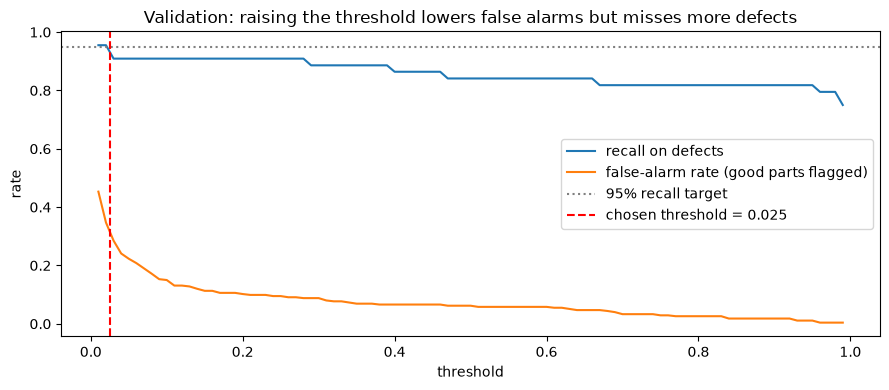

Threshold for >= 95% recall: 0.025
Validation metrics at that threshold: {'recall_defects': 0.955, 'false_alarm_rate': 0.314, 'precision': 0.328, 'missed_defects': 2, 'false_alarms': 86, 'cost_usd': 472.0, 'roc_auc': 0.955, 'pr_auc': 0.902}
(For comparison, the pure cost-minimising threshold on validation would be 0.02)


In [10]:
val_scores = predict_scores(model, val_loader)
y_val = y_all[idx_val]
model_thr = threshold_for_recall(y_val, val_scores, CFG.target_recall)

# Sweep thresholds to visualise the trade-off
grid = np.linspace(0.01, 0.99, 99)
sweep = pd.DataFrame([inspection_metrics(y_val, val_scores, t) | {"threshold": t} for t in grid])
cost_thr = float(sweep.loc[sweep["cost_usd"].idxmin(), "threshold"])

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(sweep.threshold, sweep.recall_defects, label="recall on defects")
ax1.plot(sweep.threshold, sweep.false_alarm_rate, label="false-alarm rate (good parts flagged)")
ax1.axhline(CFG.target_recall, color="grey", ls=":", label="95% recall target")
ax1.axvline(model_thr, color="red", ls="--", label=f"chosen threshold = {model_thr:.3f}")
ax1.set_xlabel("threshold"); ax1.set_ylabel("rate"); ax1.legend(loc="center right")
ax1.set_title("Validation: raising the threshold lowers false alarms but misses more defects")
plt.tight_layout(); plt.show()

print(f"Threshold for >= {CFG.target_recall:.0%} recall: {model_thr:.3f}")
print("Validation metrics at that threshold:", inspection_metrics(y_val, val_scores, model_thr))
print(f"(For comparison, the pure cost-minimising threshold on validation would be {cost_thr:.2f})")

Because a missed defect costs 75× more than a false alarm, the cost-minimising threshold and the recall-target threshold usually end up close together and far below 0.5. In practice the **quality department sets the recall target** (it is often written in the customer contract) and the ML team reports what false-alarm rate that implies.

---
## 11. Final, honest evaluation on the test set

Now, **once**, we score the test images that played no part in training, model selection or threshold choice, and compare with the classic rule at the same recall target.

Because the test set holds only 44 defects, we add a **95% confidence interval** for recall (Wilson interval). It tells the factory how sure we can be about the "95%".

                recall_defects  false_alarm_rate  precision  missed_defects  false_alarms  cost_usd  roc_auc  pr_auc
classic rule             0.977             0.704      0.182             1.0         193.0     536.0    0.791   0.488
fine-tuned CNN           0.977             0.328      0.323             1.0          90.0     330.0    0.976   0.944

CNN recall on test: 97.7% (95% CI 88.2% - 99.6%, n=44 defects)
Cost on 318 test parts: classic $536 vs CNN $330 (difference $206)


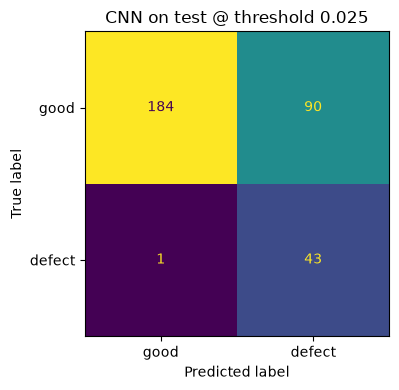

In [11]:
def wilson_interval(successes: int, n: int, z: float = 1.96):
    """95% confidence interval for a proportion (works well for small n, unlike the normal approximation)."""
    p = successes / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


test_scores = predict_scores(model, test_loader)
y_test = y_all[idx_test]
test_pred = (test_scores >= model_thr).astype(int)
model_test = inspection_metrics(y_test, test_scores, model_thr)

comparison = pd.DataFrame({"classic rule": baseline_test, "fine-tuned CNN": model_test}).T
print(comparison.to_string())

n_def = int(y_test.sum())
low, high = wilson_interval(n_def - model_test["missed_defects"], n_def)
print(f"\nCNN recall on test: {model_test['recall_defects']:.1%} (95% CI {low:.1%} - {high:.1%}, n={n_def} defects)")
saving = baseline_test["cost_usd"] - model_test["cost_usd"]
print(f"Cost on {len(y_test)} test parts: classic ${baseline_test['cost_usd']:,.0f} vs CNN ${model_test['cost_usd']:,.0f} "
      f"(difference ${saving:,.0f})")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=["good", "defect"]).plot(ax=ax, colorbar=False)
ax.set_title(f"CNN on test @ threshold {model_thr:.3f}")
plt.tight_layout(); plt.show()

**How to read this:** look at **recall** (did we hit the target?), the **false-alarm rate** (how much extra manual work?) and **cost**. Accuracy is deliberately missing: with 85% good parts it says almost nothing.

Also check the **confidence interval**: with only 44 defects, a recall measured as 95% could really be anywhere in a fairly wide range. Before going live, factories therefore run the model **in shadow mode** (it predicts, humans still decide) for a few weeks to collect more defects and narrow that interval.

### Where does the model fail? Recall per defect type and severity
An overall number hides problems. Break it down:

In [12]:
test_meta = meta.iloc[idx_test].assign(score=test_scores, flagged=test_pred)
defects = test_meta[test_meta.label == 1].copy()
defects["severity_bucket"] = pd.cut(defects.severity, [0, 0.15, 0.25, 0.36], labels=["faint (<0.15)", "medium", "strong (>0.25)"])

by_type = defects.groupby("defect_type").agg(n=("flagged", "size"), recall=("flagged", "mean")).round(3)
by_severity = defects.groupby("severity_bucket", observed=True).agg(n=("flagged", "size"), recall=("flagged", "mean")).round(3)
print("Recall by defect type:\n", by_type.to_string(), "\n")
print("Recall by severity:\n", by_severity.to_string())

Recall by defect type:
               n  recall
defect_type            
crack        17   0.941
scratch      13   1.000
spot         14   1.000 

Recall by severity:
                   n  recall
severity_bucket            
faint (<0.15)     7   1.000
medium           16   0.938
strong (>0.25)   21   1.000


In our run the CNN missed only **one** test defect (a medium-severity crack), so this table cannot reveal a pattern; with so few misses, one defect more or less changes a recall by 6-14 percentage points within a group. In real projects, with more data, misses typically concentrate in the faintest defects. This kind of table is what you bring to the quality engineers: they can decide whether a faint mark is even a real defect according to the specification, or whether the lighting setup should be improved (often the cheapest fix in visual inspection is **better light, not a better model**).

---
## 12. Error gallery: look at the mistakes

Numbers tell you *how often* the model fails; pictures tell you *why*. Always look at:
- **Missed defects** (false negatives): the expensive ones.
- **False alarms** (false positives): what confuses the model?

Missed defects: 1 | False alarms: 90


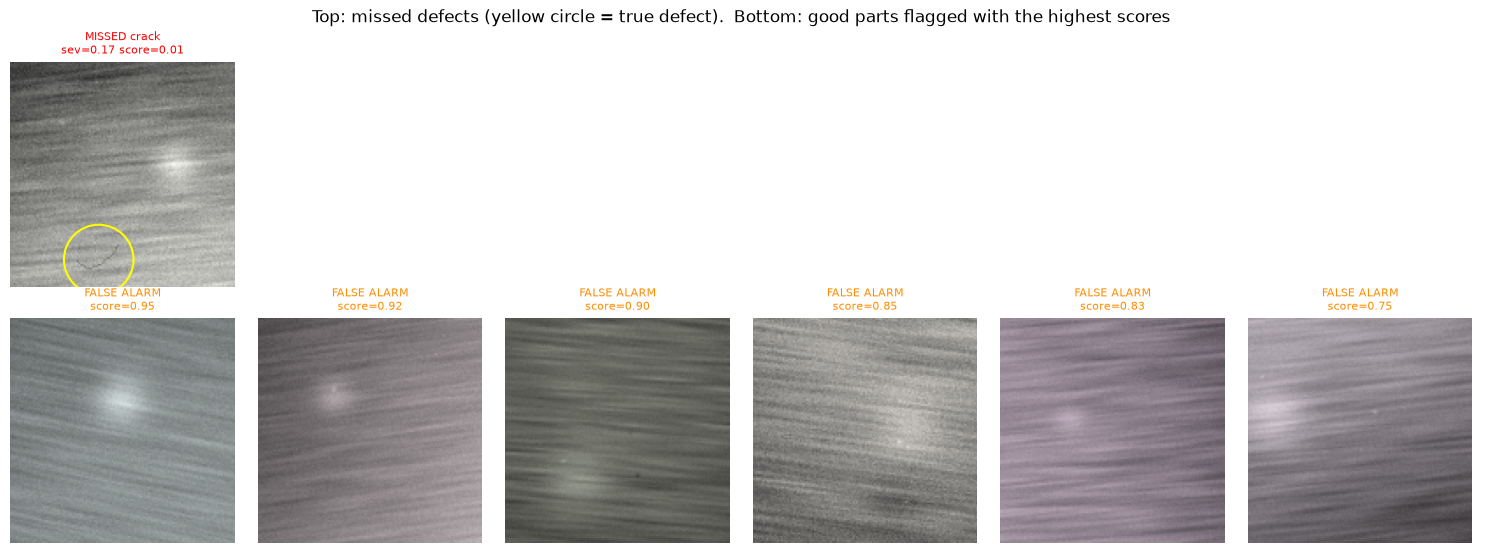

In [13]:
missed = test_meta[(test_meta.label == 1) & (test_meta.flagged == 0)].sort_values("score")
false_alarms = test_meta[(test_meta.label == 0) & (test_meta.flagged == 1)].sort_values("score", ascending=False)
print(f"Missed defects: {len(missed)} | False alarms: {len(false_alarms)}")

n_cols = 6
fig, axes = plt.subplots(2, n_cols, figsize=(15, 5.6))
for ax in axes.ravel():
    ax.axis("off")
for ax, (i, row) in zip(axes[0], missed.head(n_cols).iterrows()):
    ax.imshow(images[i])
    ax.add_patch(plt.Circle((row.defect_x, row.defect_y), row.defect_extent + 6, color="yellow", fill=False, lw=1.5))  # true location
    ax.set_title(f"MISSED {row.defect_type}\nsev={row.severity:.2f} score={row.score:.2f}", fontsize=8, color="red")
for ax, (i, row) in zip(axes[1], false_alarms.head(n_cols).iterrows()):
    ax.imshow(images[i])
    ax.set_title(f"FALSE ALARM\nscore={row.score:.2f}", fontsize=8, color="darkorange")
plt.suptitle("Top: missed defects (yellow circle = true defect).  Bottom: good parts flagged with the highest scores")
plt.tight_layout(); plt.show()

What the pictures show in our run: the missed defect is a thin, low-contrast crack in a darker part of the image that blends into the brushed texture, and the highest-scoring false alarms are dominated by **lamp glare** (bright soft spots). That is a very actionable finding: a diffuser or polariser on the lamp, or more glare examples in the training data, would attack the biggest source of false alarms. In a real project you would now (1) ask whether the faint ones are real defects according to the spec, (2) collect more examples of the confusing cases, and (3) possibly re-label: error galleries often reveal **wrong labels** in the training data.

---
## 13. Explain the model with Grad-CAM

**Grad-CAM** highlights the image regions that pushed the model towards "defect". It answers: *is the model right for the right reasons?* A model that looks at the image border or at the glare instead of the scratch is a model that will fail in production.

How it works in one sentence: take the feature maps of a late convolutional layer, weight each map by how much the "defect" score increases when that map increases (its average gradient), sum them up and keep the positive part.

We use the layer `model.features[8]` (an 8×8 grid for a 128×128 image; the very last layer is only 4×4, too coarse for tiny defects). Libraries such as `pytorch-grad-cam` do this for you; here are the ~20 lines so you can see there is no magic.

Because our images know where the defect really is, we can even **measure** whether the heatmap points at it.

In [14]:
class GradCAM:
    """Minimal Grad-CAM for a single-logit classifier."""

    def __init__(self, model, layer):
        self.model, self.activations, self.gradients = model, None, None
        layer.register_forward_hook(self._save_activation)            # called on every forward pass

    def _save_activation(self, module, inputs, output):
        if output.requires_grad:                                       # skip normal no-grad predictions
            self.activations = output
            output.register_hook(self._save_gradient)                  # called when gradients flow back

    def _save_gradient(self, grad):
        self.gradients = grad

    def heatmap(self, image: np.ndarray) -> np.ndarray:
        self.model.eval()
        x = EVAL_TRANSFORM(image).unsqueeze(0).requires_grad_(True)   # same preprocessing as always
        logit = self.model(x).squeeze()
        self.model.zero_grad()
        logit.backward()                                                # gradient of the "defect" score
        weights_ = self.gradients.mean(dim=(2, 3), keepdim=True)        # importance of each feature map
        cam = torch.relu((weights_ * self.activations).sum(dim=1)).squeeze(0).detach().numpy()
        cam = cv2.resize(cam, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_LINEAR)
        return cam / (cam.max() + 1e-8)                                 # scale to 0..1


grad_cam = GradCAM(model, model.features[8])
caught = test_meta[(test_meta.label == 1) & (test_meta.flagged == 1)]

# Quantitative check: is the hottest point of the heatmap close to the true defect?
hits = []
for i, row in caught.iterrows():
    cam = grad_cam.heatmap(images[i])
    peak_y, peak_x = np.unravel_index(cam.argmax(), cam.shape)
    hits.append(np.hypot(peak_x - row.defect_x, peak_y - row.defect_y) <= row.defect_extent + 16)   # + one grid cell
print(f"Grad-CAM peak on (or within 16 px of) the true defect for {np.mean(hits):.0%} of {len(hits)} caught defects")

Grad-CAM peak on (or within 16 px of) the true defect for 37% of 43 caught defects


Look at the percentage: in our run the Grad-CAM peak lands on the defect for only around a third of the caught defects, and the heatmaps (shown below) are blotchy. Does that mean the model is "cheating"? **Not necessarily**: Grad-CAM on a mid-level layer of a small network is often noisy, and our defects are tiny compared with its 16×16-pixel cells. An explanation method can be wrong too, so before trusting (or distrusting) the model, get a **second opinion**.

### 13b. Second opinion: occlusion sensitivity
**Occlusion sensitivity** is the most direct test, and works for any model: cover one patch of the image (here with a blurred copy of itself, so we remove fine detail but not the overall brightness), and measure how much the model's defect score (logit) drops. If covering the defect makes the score collapse, the model really uses the defect. It needs one forward pass per patch (64 here), so it is slower than Grad-CAM, but it is easy to understand and hard to fool.

Occlusion peak on (or within 16 px of) the true defect for 88% of 43 caught defects (12s)
Grad-CAM, same check                                 : 37%


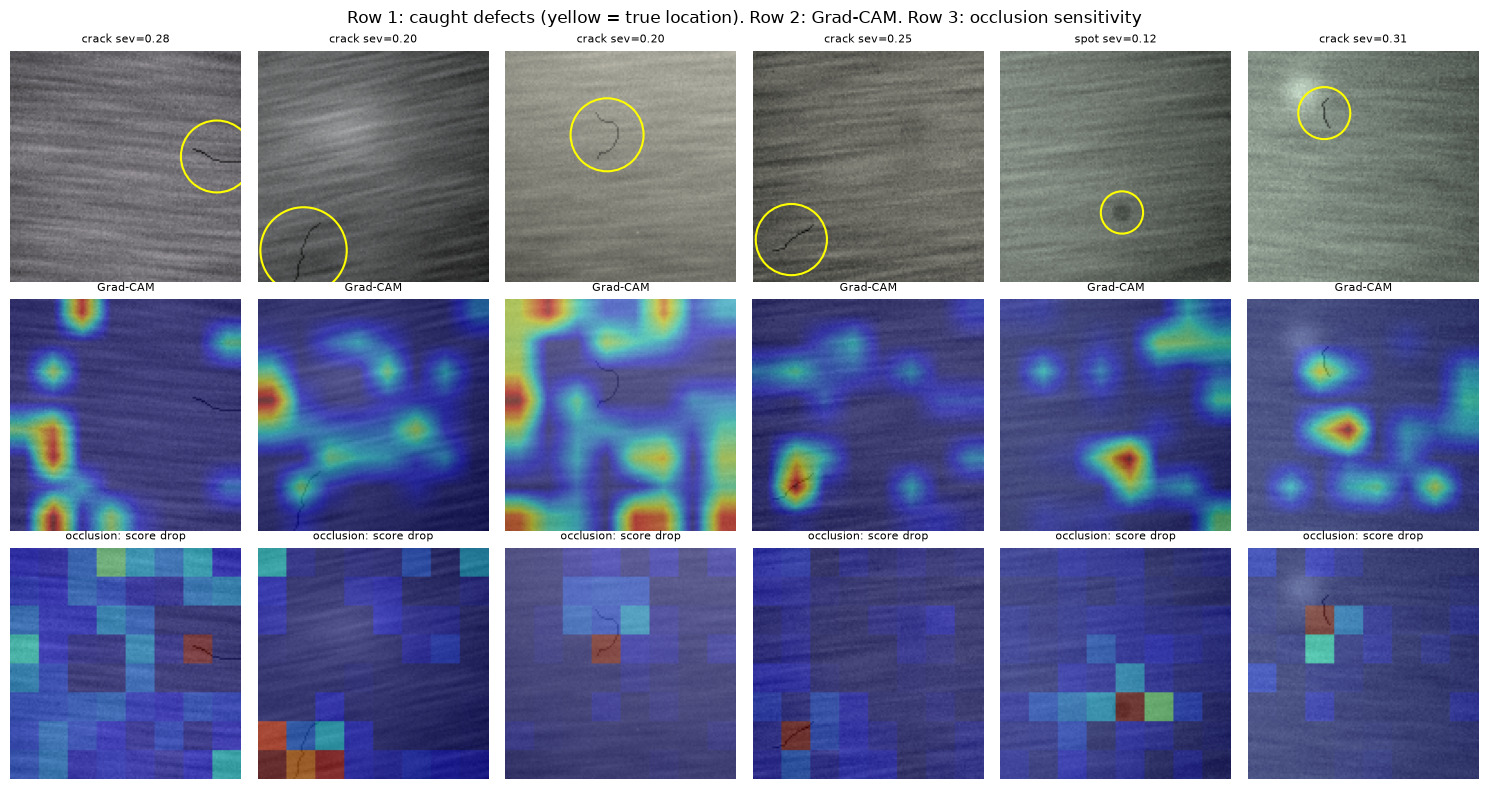

In [15]:
@torch.inference_mode()
def occlusion_map(image: np.ndarray, patch: int = 16) -> np.ndarray:
    """Drop in the defect logit when each 16x16 patch is replaced by a blurred version of itself."""
    blurred = cv2.blur(image, (31, 31))                                   # fine details removed, brightness kept
    base = model(EVAL_TRANSFORM(image)[None]).item()                      # logit of the untouched image
    corners = [(y, x) for y in range(0, SIZE, patch) for x in range(0, SIZE, patch)]
    batch = []
    for y, x in corners:
        occluded = image.copy()
        occluded[y:y + patch, x:x + patch] = blurred[y:y + patch, x:x + patch]
        batch.append(EVAL_TRANSFORM(occluded))
    drops = base - model(torch.stack(batch)).squeeze(1).numpy()           # big drop = important patch
    heat = np.zeros((SIZE, SIZE), np.float32)
    for (y, x), d in zip(corners, drops):
        heat[y:y + patch, x:x + patch] = d
    return heat


model.eval()
t0 = time.time()
occ_hits = []
for i, row in caught.iterrows():
    heat = occlusion_map(images[i])
    peak_y, peak_x = np.unravel_index(heat.argmax(), heat.shape)
    occ_hits.append(np.hypot(peak_x - row.defect_x, peak_y - row.defect_y) <= row.defect_extent + 16)
print(f"Occlusion peak on (or within 16 px of) the true defect for {np.mean(occ_hits):.0%} of {len(occ_hits)} "
      f"caught defects ({time.time() - t0:.0f}s)")
print(f"Grad-CAM, same check                                 : {np.mean(hits):.0%}")

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for col, (i, row) in enumerate(caught.sample(6, random_state=1).iterrows()):
    axes[0, col].imshow(images[i]); axes[0, col].set_title(f"{row.defect_type} sev={row.severity:.2f}", fontsize=8)
    axes[0, col].add_patch(plt.Circle((row.defect_x, row.defect_y), row.defect_extent + 6, color="yellow", fill=False, lw=1.5))
    axes[1, col].imshow(images[i]); axes[1, col].imshow(grad_cam.heatmap(images[i]), cmap="jet", alpha=0.45)
    axes[1, col].set_title("Grad-CAM", fontsize=8)
    axes[2, col].imshow(images[i]); axes[2, col].imshow(np.clip(occlusion_map(images[i]), 0, None), cmap="jet", alpha=0.45)
    axes[2, col].set_title("occlusion: score drop", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Row 1: caught defects (yellow = true location). Row 2: Grad-CAM. Row 3: occlusion sensitivity")
plt.tight_layout(); plt.show()

Compare the two percentages and rows 2 and 3. In our run, occlusion points at the real defect far more often than Grad-CAM: the model **does** rely on the defect pixels, and it was the Grad-CAM heatmap that was too noisy to show it. Lessons:
- **Validate your explanation method** before drawing conclusions from it (here we could, because we know where the defects are).
- Grad-CAM is fast and fine for a quick look; occlusion is slower but more trustworthy for tiny objects.
- Explanations are coarse either way. For pixel-accurate localisation, industry uses segmentation models or anomaly-detection methods such as PatchCore / PaDiM (see the `anomalib` library), which also have the big advantage of needing **only good parts** for training.

In [16]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="defect_inspector_"))      # real life: models/defect_inspector/v1/
WEIGHTS_PATH = ARTIFACT_DIR / "model_state_dict.pt"
METADATA_PATH = ARTIFACT_DIR / "metadata.json"

torch.save(model.state_dict(), WEIGHTS_PATH)

metadata = {
    "model_name": "surface_defect_inspector",
    "model_version": "1.0.0",
    "architecture": "torchvision mobilenet_v3_small, classifier[3] -> Linear(1024, 1)",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "torch_version": torch.__version__, "torchvision_version": torchvision.__version__,
    "input": {"shape_hwc": list(EXPECTED_SHAPE), "dtype": "uint8", "channel_order": "RGB",
              "normalize_mean": list(IMAGENET_MEAN), "normalize_std": list(IMAGENET_STD)},
    "decision_threshold": model_thr,
    "target_recall": CFG.target_recall,
    "test_metrics": model_test,
    "n_train_images": int(len(idx_train)),
    "config": asdict(CFG),
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2, default=str))
for f in ARTIFACT_DIR.iterdir():
    print(f"{f.name:22s} {f.stat().st_size / 1024:8.1f} KB")

model_state_dict.pt      6062.7 KB
metadata.json               1.3 KB


> **Deployment formats:** for the factory PC you might export the model to **ONNX** (`torch.onnx.export`) and run it with ONNX Runtime or OpenVINO, which are often 2-3× faster on CPUs. Whatever the format, the preprocessing recorded in the metadata must travel with it. See `16_Deployment/04_edge_deployment.ipynb`.

---
## 15. Serve the model: an inference function for one image

The inspection station sends **one image at a time**. The serving code must:
1. **Load once** at start-up (not per image).
2. **Validate** the image with the *same* `validate_image` function used for training data. An invalid image is never scored; it is routed to a human.
3. **Preprocess identically** to training: we reuse `EVAL_TRANSFORM` instead of re-writing it (a re-written copy is where bugs creep in).
4. Return a clear decision with the score, the threshold and the model version (for traceability).

In [17]:
class DefectInspector:
    """Loads the saved model once and inspects single images."""

    def __init__(self, artifact_dir: Path):
        self.metadata = json.loads((artifact_dir / "metadata.json").read_text())
        self.model = build_model(pretrained=False)                      # architecture only, no download
        self.model.load_state_dict(torch.load(artifact_dir / "model_state_dict.pt", weights_only=True))
        self.model.eval()
        self.threshold = self.metadata["decision_threshold"]
        log.info("Loaded %s v%s (threshold %.3f)", self.metadata["model_name"],
                 self.metadata["model_version"], self.threshold)

    @staticmethod
    def preprocess(image: np.ndarray) -> torch.Tensor:
        return EVAL_TRANSFORM(image).unsqueeze(0)                        # SAME transform as validation/test

    @torch.inference_mode()
    def inspect(self, image: np.ndarray, part_id: str = "unknown") -> dict:
        problems = validate_image(image)
        if problems:                                                     # never score a broken image
            return {"part_id": part_id, "decision": "MANUAL_CHECK", "reason": problems,
                    "model_version": self.metadata["model_version"]}
        score = torch.sigmoid(self.model(self.preprocess(image))).item()
        return {"part_id": part_id,
                "decision": "REJECT" if score >= self.threshold else "PASS",
                "defect_score": round(score, 4),
                "threshold": round(self.threshold, 4),
                "model_version": self.metadata["model_version"]}


inspector = DefectInspector(ARTIFACT_DIR)                                # simulates the station starting up
good_example = idx_test[np.flatnonzero(y_test == 0)[0]]
defect_example = caught.index[0]
print(inspector.inspect(images[good_example], meta.part_id[good_example]))
print(inspector.inspect(images[defect_example], meta.part_id[defect_example]))
print(inspector.inspect(np.zeros((128, 128, 3), np.uint8), "P-black-frame"))       # camera dropout
print(inspector.inspect(images[good_example][:, :, 0], "P-grayscale"))             # wrong format

2026-10-21 17:51:43,025 | INFO | Loaded surface_defect_inspector v1.0.0 (threshold 0.025)


{'part_id': 'P101544', 'decision': 'PASS', 'defect_score': 0.0052, 'threshold': 0.0252, 'model_version': '1.0.0'}
{'part_id': 'P101348', 'decision': 'REJECT', 'defect_score': 1.0, 'threshold': 0.0252, 'model_version': '1.0.0'}
{'part_id': 'P-black-frame', 'decision': 'MANUAL_CHECK', 'reason': ['too dark (mean=0) - camera dropout?', 'almost no texture (std=0.0) - frozen frame?'], 'model_version': '1.0.0'}
{'part_id': 'P-grayscale', 'decision': 'MANUAL_CHECK', 'reason': ['shape (128, 128) != (128, 128, 3)'], 'model_version': '1.0.0'}


---
## 16. Latency check

The line needs an answer within **200 ms** per part. We measure:
- **single-image latency** (what one inspection station experiences), reporting the median (p50) and the **p95** (the slow cases matter: a slow answer can stop the line),
- **batch throughput** (useful if several cameras share one PC).

Always measure on hardware similar to production, after a few **warm-up** runs (the first calls are slower).

In [18]:
sample = images[idx_test[0]]
for _ in range(5):
    inspector.inspect(sample)                                    # warm-up

timings_ms = []
for _ in range(50):
    t0 = time.perf_counter()
    inspector.inspect(sample)                                    # validation + preprocessing + model
    timings_ms.append((time.perf_counter() - t0) * 1000)
p50, p95 = np.percentile(timings_ms, [50, 95])

batch = torch.stack([EVAL_TRANSFORM(im) for im in images[idx_test[:32]]])
with torch.inference_mode():
    t0 = time.perf_counter(); inspector.model(batch); batch_s = time.perf_counter() - t0

print(f"Single image: p50 = {p50:.1f} ms | p95 = {p95:.1f} ms | budget = {CFG.latency_budget_ms:.0f} ms "
      f"-> {'OK' if p95 < CFG.latency_budget_ms else 'TOO SLOW'}")
print(f"Batch of 32 : {batch_s * 1000:.0f} ms total = {32 / batch_s:.0f} images/second")

Single image: p50 = 52.5 ms | p95 = 207.5 ms | budget = 200 ms -> TOO SLOW
Batch of 32 : 361 ms total = 89 images/second


Latency numbers depend on the machine and on what else is running on it. This notebook was executed on a busy, shared CPU: the median (p50) is far below the budget, but the p95 is sensitive to other jobs stealing the CPU and may land near or even above 200 ms in the saved output. That is exactly why the inspection PC at the line should be **dedicated** to this job, and why we always report p95 and not only the average. If the model were too slow, typical fixes are: smaller input size, a smaller backbone, ONNX Runtime / OpenVINO, int8 quantisation (see `05_Deep_Learning/08_model_compression.ipynb`), or batching several cameras together.

---
## 17. Automated tests

Like any software, the inspection model gets tests that run automatically before every release (normally with `pytest` in a `tests/` folder; see `15_MLOps/07_testing_in_ml/01_testing_ml.ipynb`).

In [19]:
def test_serving_preprocessing_matches_evaluation():
    """The tensor the service feeds the model must equal the tensor used during evaluation."""
    x_eval, _ = test_loader.dataset[0]
    x_serve = DefectInspector.preprocess(images[idx_test[0]])[0]
    assert torch.equal(x_eval, x_serve)


def test_service_scores_match_evaluation():
    """Reloaded model + service must reproduce the evaluation scores exactly (up to float noise)."""
    served = [inspector.inspect(images[i])["defect_score"] for i in idx_test[:20]]
    assert np.allclose(served, test_scores[:20], atol=1e-3)


def test_rejects_invalid_images():
    assert inspector.inspect(np.full((128, 128, 3), 255, np.uint8))["decision"] == "MANUAL_CHECK"
    assert inspector.inspect(np.zeros((64, 64, 3), np.uint8))["decision"] == "MANUAL_CHECK"
    assert inspector.inspect("not an image")["decision"] == "MANUAL_CHECK"


def test_flip_invariance():
    """A flipped part is the same part: the score should barely change (we trained with flips)."""
    img = images[defect_example]
    a = inspector.inspect(img)["defect_score"]
    b = inspector.inspect(np.ascontiguousarray(img[:, ::-1]))["defect_score"]
    assert abs(a - b) < 0.25, (a, b)


def test_quality_gate():
    """Never release a model that is worse than the classic rule on the test set."""
    assert model_test["cost_usd"] <= baseline_test["cost_usd"]
    assert model_test["pr_auc"] > baseline_test["pr_auc"]


for test in [test_serving_preprocessing_matches_evaluation, test_service_scores_match_evaluation,
             test_rejects_invalid_images, test_flip_invariance, test_quality_gate]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_serving_preprocessing_matches_evaluation


PASSED  test_service_scores_match_evaluation
PASSED  test_rejects_invalid_images
PASSED  test_flip_invariance
PASSED  test_quality_gate


---
## 18. Monitoring: what happens when the lamp gets darker?

Inspection lamps age, cameras get dusty, a new supplier delivers slightly shinier metal. The model was never trained on these conditions. Two monitoring habits help:
1. **Watch the inputs:** track simple image statistics (mean brightness, contrast) per hour and alert when they leave the training range.
2. **Watch the outputs:** track the **reject rate**. If it suddenly doubles, either production has a real problem or the model is confused, and both need a human.

Below we simulate a lamp that lost 35% of its brightness and re-score the test images.

In [20]:
darker = (images[idx_test].astype(np.float32) * 0.65).astype(np.uint8)          # aged lamp
dark_loader = torch.utils.data.DataLoader(SurfaceDataset(darker, y_test, EVAL_TRANSFORM), batch_size=CFG.batch_size)
dark_scores = predict_scores(model, dark_loader)
dark_metrics = inspection_metrics(y_test, dark_scores, model_thr)

train_brightness = images[idx_train].mean(axis=(1, 2, 3))
low_b, high_b = np.percentile(train_brightness, [1, 99])                          # "normal" range from training
monitor = pd.DataFrame({
    "mean brightness": [images[idx_test].mean(), darker.mean()],
    "share of images outside training brightness range": [
        np.mean((images[idx_test].mean(axis=(1, 2, 3)) < low_b) | (images[idx_test].mean(axis=(1, 2, 3)) > high_b)),
        np.mean((darker.mean(axis=(1, 2, 3)) < low_b) | (darker.mean(axis=(1, 2, 3)) > high_b))],
    "reject rate": [test_pred.mean(), (dark_scores >= model_thr).mean()],
    "recall on defects": [model_test["recall_defects"], dark_metrics["recall_defects"]],
    "false-alarm rate": [model_test["false_alarm_rate"], dark_metrics["false_alarm_rate"]],
}, index=["normal lamp", "aged lamp (-35%)"]).round(3)
monitor

,mean brightness,share of images outside training brightness range,reject rate,recall on defects,false-alarm rate
normal lamp,129.979,0.031,0.418,0.977,0.328
aged lamp (-35%),84.008,0.664,0.368,0.977,0.270


The input monitor (share of images outside the training brightness range) reacts immediately, **before** anyone has to find out the hard way through customer returns. In our run the model itself coped well with the darker lamp (same recall, slightly fewer false alarms), thanks to the brightness augmentation in training. That is good news, but notice that **we could only know this because we had labels**; on the real line you would not, so the alert is still correct: a human should check a sample of parts whenever the inputs leave the training range. Typical responses: fix the lamp (cheapest), add stronger brightness augmentation, or collect new images and retrain.

---
## 19. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Central config + seeds | `Config` dataclass | Every reproducible ML project |
| Image validation | shape / dtype / brightness / duplicates | Before training **and** before every prediction |
| Stratified split, test used once | train / val / test | Honest performance estimate |
| Realistic augmentation only | flips, small shifts, lighting | Avoids teaching the model impossible images |
| Baseline first | classic background-subtraction rule | Proves the CNN is worth its complexity |
| Transfer learning | frozen head (cached features) → full fine-tune | Standard for small image datasets |
| Class imbalance | `pos_weight` in the loss | Rare defects, fraud, disease |
| Threshold by business rule | ≥ 95% recall on validation | Quality targets in contracts |
| Uncertainty | Wilson interval on recall | Small test sets in factories / medicine |
| Error analysis | per type / severity + error gallery | Finding label errors and lighting problems |
| Explainability | Grad-CAM vs occlusion, checked against true defect positions | Trust from quality engineers |
| Saving | `state_dict` + metadata JSON | Model registry, traceability |
| Serving | `DefectInspector` reusing the same transform | Edge PC at the line |
| Latency | p50 / p95, batch throughput | Real-time systems |
| Tests + monitoring | equality tests, quality gate, brightness drift | CI/CD and production monitoring |

### Practice exercises
1. Change `cost_missed_defect` and `target_recall` in the config. How do the threshold and false-alarm rate move?
2. Replace `pos_weight` with a `WeightedRandomSampler` (oversampling). Does validation PR-AUC change?
3. Swap MobileNetV3-Small for `torchvision.models.resnet18` (≈45 MB download) and compare quality **and** latency.
4. Increase the image size the model sees (e.g. `T.Resize(192)` in **both** transforms) and check if faint defects are found more often. What happens to latency?
5. Anomaly-detection approach: train on **good parts only** by fitting a Gaussian to the frozen backbone features and scoring the Mahalanobis distance (the idea behind PaDiM). Compare with the classifier.

### Resources
- PyTorch tutorial, *Transfer Learning for Computer Vision* (freeze vs fine-tune, best-checkpoint logic): https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
- MVTec AD, the industrial anomaly-detection benchmark: https://www.mvtec.com/company/research/datasets/mvtec-ad
- `anomalib`, a library of industrial anomaly-detection models (PatchCore, PaDiM, ...): https://github.com/open-edge-platform/anomalib
- `pytorch-grad-cam`, Grad-CAM and friends for any PyTorch model: https://github.com/jacobgil/pytorch-grad-cam
- `timm` (PyTorch Image Models), hundreds of pretrained backbones: https://huggingface.co/docs/timm
- Grad-CAM paper (Selvaraju et al., 2017): https://arxiv.org/abs/1610.02391

### Related notebooks in this repo
- Theory of CNNs, augmentation, transfer learning, Grad-CAM: [`02_image_classification.ipynb`](02_image_classification.ipynb), [`../05_Deep_Learning/03_cnn.ipynb`](../05_Deep_Learning/03_cnn.ipynb)
- Classic image processing (filters, edges, morphology): [`01_image_basics_opencv.ipynb`](01_image_basics_opencv.ipynb)
- Class imbalance and evaluation in a high-stakes domain: [`10_medical_image_analysis.ipynb`](10_medical_image_analysis.ipynb)
- Making models smaller and faster: [`../05_Deep_Learning/08_model_compression.ipynb`](../05_Deep_Learning/08_model_compression.ipynb)
- Running models on edge devices: [`../16_Deployment/04_edge_deployment.ipynb`](../16_Deployment/04_edge_deployment.ipynb)
- Testing and monitoring ML systems: [`../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb`](../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb), [`../15_MLOps/06_monitoring/01_monitoring.ipynb`](../15_MLOps/06_monitoring/01_monitoring.ipynb)
- Next: [`12_industry_visual_product_search.ipynb`](12_industry_visual_product_search.ipynb) (image embeddings + FAISS)